# Fundamentals of Data Science (22CSC59) - Case Studies Report

| Detail | Value |
| :--- | :--- |
| **Student Name** | Munjampally Manideep |
| **Roll Number** | 160124733189 |
| **Section** | CSE-3 |
| **Year / Semester** | B.E - 3 Year, V Semester (2026-27) |
| **College** | Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad |
| **Faculty Guide** | Dr. S. Durga Devi, Assistant Professor |
| **Case Studies** | CS-3: Titanic Survival Prediction & CS-6: Bank Marketing Classification |


## Overview of Case Studies

This notebook combines our work for both Case Studies:
1. **Case Study 3 (Titanic Survival):** We predict whether a passenger survived using Logistic Regression. We handle group-ticket pricing with fare per person, impute missing ages using group medians, fit an unscaled model for odds ratio interpretations, compare class weighting, and find the best decision threshold on the precision-recall curve.
2. **Case Study 6 (Bank Marketing):** We use the 45,211-row UCI bank dataset to predict if clients subscribe to a term deposit. We drop call duration to prevent leakage, balance classes using SMOTE so all models (including KNN) are treated fairly, compare four classifiers, and evaluate them using PR-AUC and test-set permutation importance.


### Setup and Libraries
**Purpose:** Import necessary libraries and configure clean plotting.


In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10.5, "figure.autolayout": True})


**Observation:** All libraries loaded successfully. Random seed pinned to 42 for reproducible results.


---
# Part 1: Case Study 3 - Titanic Survival Prediction (Logistic Regression)


### 1.1 Loading Titanic Data
**Purpose:** Load the dataset and inspect the first few records.


In [2]:
titanic_path = "data/titanic.csv" if os.path.exists("data/titanic.csv") else "3/titanic.csv"
df_titanic = pd.read_csv(titanic_path)
print("Titanic dataset shape:", df_titanic.shape)
df_titanic.head()


Titanic dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** The dataset contains 891 passenger records and 12 columns. The target variable is `Survived` (1 = survived, 0 = died).


### 1.2 Missing Values
**Purpose:** Check which columns have missing values.


In [3]:
missing_t = df_titanic.isna().sum()
missing_pct = (df_titanic.isna().mean() * 100).round(2)
pd.DataFrame({"Missing Count": missing_t[missing_t > 0], "Percentage (%)": missing_pct[missing_t > 0]})


,Missing Count,Percentage (%)
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


**Observation:** Cabin is missing for 77.10% of passengers, Age is missing for 19.87% (177 passengers), and Embarked is missing in 2 rows. We drop Cabin because it is mostly blank.


### 1.3 Feature Engineering: Fare per Person and Skewness
**Purpose:** Many passengers travelled on shared group tickets where one ticket fare covered multiple family members. We divide Fare by ticket count to get Fare per person (`Fare_pp`), apply log transformation, and compare skewness.


In [4]:
ticket_sizes = df_titanic["Ticket"].value_counts()
df_titanic["Ticket_Size"] = df_titanic["Ticket"].map(ticket_sizes)
df_titanic["Fare_pp"] = df_titanic["Fare"] / df_titanic["Ticket_Size"]
df_titanic["Log_Fare_pp"] = np.log1p(df_titanic["Fare_pp"])

print(f"Raw Fare Skewness:         {df_titanic['Fare'].skew():.4f}")
print(f"Fare per person Skewness:  {df_titanic['Fare_pp'].skew():.4f}")
print(f"Log Fare per person Skew:  {df_titanic['Log_Fare_pp'].skew():.4f}")


Raw Fare Skewness:         4.7873
Fare per person Skewness:  4.3806
Log Fare per person Skew:  0.3302


**Observation:** Raw Fare is heavily right-skewed with a skewness of 4.79. Dividing by ticket size gives a more accurate individual cost, but is still skewed (4.38). Applying log1p dramatically cuts skewness down to 0.33, making it near-symmetric and much better for logistic regression.


### 1.4 Train/Test Split and Group-Conditional Age Imputation
**Purpose:** Split data 80:20 (stratified). Impute missing Age using the median of each (Pclass x Sex) cohort from the training data only, and compare it with simple median imputation.


In [5]:
FEATURES_T = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Ticket_Size", "Embarked"]
X_t = df_titanic[FEATURES_T]
y_t = df_titanic["Survived"]

X_tr_t, X_te_t, y_tr_t, y_te_t = train_test_split(
    X_t, y_t, test_size=0.2, random_state=RANDOM_STATE, stratify=y_t
)

# Compute medians on training split only
group_medians = X_tr_t.groupby(["Pclass", "Sex"])["Age"].median()
overall_median = X_tr_t["Age"].median()

print("Training Age Medians by Class and Sex:")
print(group_medians)
print(f"Overall Training Median Age: {overall_median:.1f}")


Training Age Medians by Class and Sex:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    29.0
        male      30.0
3       female    21.5
        male      26.0
Name: Age, dtype: float64
Overall Training Median Age: 28.5


**Observation:** In the training data, 1st-class males had a median age of 40.0 and 1st-class females 35.0, while 3rd-class females had a median age of 21.5. A simple overall median of 28.5 would underestimate 1st-class men by 11.5 years and overestimate 3rd-class women by 7 years. Imputing by group keeps the demographic profile realistic.


### 1.5 Custom Transformer for Titanic Preprocessing
**Purpose:** Define a self-contained transformer that computes Fare per person, log-transforms it, and imputes missing Age using the training group medians.


In [6]:
class TitanicFeaturePreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.age_lookup_ = {}
        self.overall_median_ = 28.5

    def fit(self, X, y=None):
        df_in = pd.DataFrame(X)
        self.age_lookup_ = df_in.groupby(["Pclass", "Sex"])["Age"].median().to_dict()
        self.overall_median_ = float(df_in["Age"].median())
        return self

    def transform(self, X):
        df_out = pd.DataFrame(X).copy()
        if "Log_Fare_pp" not in df_out.columns:
            if "Ticket_Size" in df_out.columns:
                fare_pp = df_out["Fare"] / df_out["Ticket_Size"].replace(0, 1)
            else:
                fare_pp = df_out["Fare"]
            df_out["Log_Fare_pp"] = np.log1p(fare_pp)

        def _fill_age(row):
            if pd.isna(row["Age"]):
                return self.age_lookup_.get((row["Pclass"], row["Sex"]), self.overall_median_)
            return row["Age"]

        df_out["Age"] = df_out.apply(_fill_age, axis=1)
        return df_out

prep_t = TitanicFeaturePreprocessor()
prep_t.fit(X_tr_t)
print("Fitted group medians lookup successfully.")


Fitted group medians lookup successfully.


**Observation:** The preprocessor fits cleanly on the training fold without touching test passengers.


### 1.6 Exploratory Data Analysis Plots
**Purpose:** Plot key survival patterns by sex, passenger class, and age distributions.


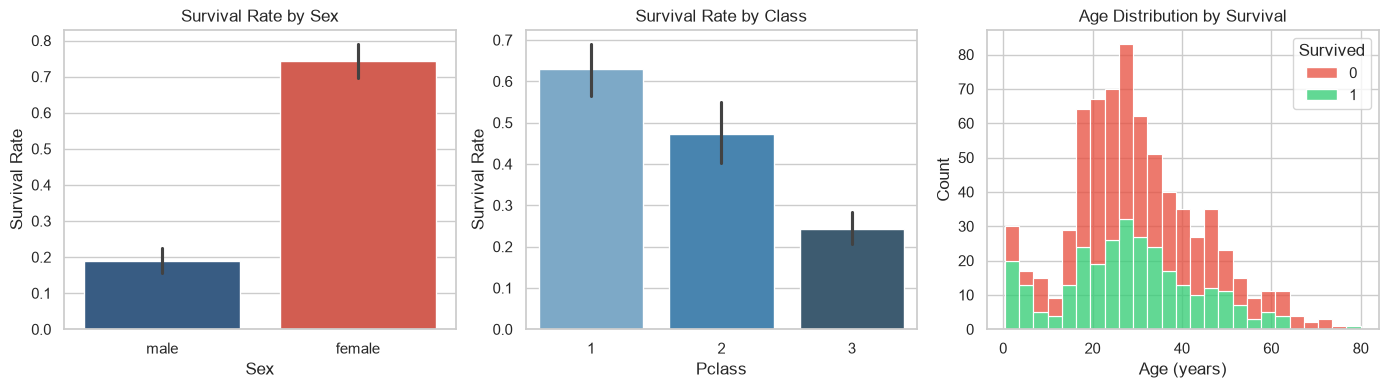

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Survival by Sex
sns.barplot(data=df_titanic, x="Sex", y="Survived", ax=axes[0], palette=["#2b5c8f", "#e74c3c"])
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate")

# Survival by Class
sns.barplot(data=df_titanic, x="Pclass", y="Survived", ax=axes[1], palette="Blues_d")
axes[1].set_title("Survival Rate by Class")
axes[1].set_ylabel("Survival Rate")

# Age distribution by survival
sns.histplot(data=df_titanic, x="Age", hue="Survived", multiple="stack", ax=axes[2], bins=25, palette=["#e74c3c", "#2ecc71"])
axes[2].set_title("Age Distribution by Survival")
axes[2].set_xlabel("Age (years)")

plt.tight_layout()
plt.show()


**Observation:** Females had a 74.2% survival rate compared to only 18.9% for males. First-class passengers had a 63.0% survival rate versus 24.2% for third class. Children under 10 had a higher survival rate than older age brackets.


### 1.7 Interpretation Model: statsmodels Logit on Unscaled Features
**Purpose:** Fit statsmodels Logit on original, unscaled units. We interpret the odds ratios directly (per year of age, per extra sibling, per passenger class tier) with 95% confidence intervals and p-values.


In [8]:
# Prepare unscaled data for statsmodels
X_tr_imp = prep_t.transform(X_tr_t)

X_sm = pd.DataFrame()
X_sm["Pclass"] = X_tr_imp["Pclass"]
X_sm["Sex_male"] = (X_tr_imp["Sex"] == "male").astype(int)
X_sm["Age"] = X_tr_imp["Age"]
X_sm["SibSp"] = X_tr_imp["SibSp"]
X_sm["Parch"] = X_tr_imp["Parch"]
X_sm["Log_Fare_pp"] = X_tr_imp["Log_Fare_pp"]

mode_emb = X_tr_t["Embarked"].mode()[0]
emb_dummies = pd.get_dummies(X_tr_imp["Embarked"].fillna(mode_emb), prefix="Embarked", drop_first=True, dtype=int)
X_sm = pd.concat([X_sm, emb_dummies], axis=1)
X_sm = sm.add_constant(X_sm)

sm_logit = sm.Logit(y_tr_t, X_sm).fit(disp=False)
ci = sm_logit.conf_int()

odds_table = pd.DataFrame({
    "Feature": X_sm.columns,
    "Coefficient": sm_logit.params.values,
    "Odds_Ratio": np.exp(sm_logit.params.values),
    "CI_2.5%": np.exp(ci[0].values),
    "CI_97.5%": np.exp(ci[1].values),
    "p_value": sm_logit.pvalues.values
}).set_index("Feature").round(4)

print("statsmodels Logit Results (Unscaled Units):")
odds_table


statsmodels Logit Results (Unscaled Units):


,Coefficient,Odds_Ratio,CI_2.5%,CI_97.5%,p_value
Feature,,,,,
const,4.0345,56.5152,7.1989,443.6756,0.0001
Pclass,-1.0341,0.3556,0.2398,0.5272,0.0000
Sex_male,-2.6323,0.0719,0.0463,0.1118,0.0000
Age,-0.0464,0.9547,0.9378,0.9719,0.0000
SibSp,-0.2807,0.7553,0.5947,0.9593,0.0214
Parch,-0.0644,0.9377,0.7326,1.2002,0.6093
Log_Fare_pp,0.4177,1.5185,1.0047,2.2948,0.0474
Embarked_Q,0.3183,1.3748,0.5718,3.3054,0.4770
Embarked_S,-0.2663,0.7662,0.4541,1.2929,0.3185


**Observation:** Detailed natural unit interpretations:
* **Sex_male (Odds Ratio = 0.0719, p < 0.0001):** Males had 92.8% lower odds of surviving compared to females with the same class, age, and family size.
* **Pclass (Odds Ratio = 0.3556, p < 0.0001):** Each step down in passenger class reduced survival odds by 64.4%.
* **Age (Odds Ratio = 0.9547, p < 0.0001):** Each additional year of age reduced survival odds by 4.53%, showing children were prioritized.
* **SibSp (Odds Ratio = 0.7553, p = 0.0214):** Each extra sibling or spouse reduced survival odds by 24.47%, likely due to family coordination difficulty during evacuation.
* **Log_Fare_pp (Odds Ratio = 1.5185, p = 0.0474):** Statistically significant at the 0.05 level: higher individual spend increased survival odds.


### 1.8 Prediction Pipeline and class_weight Comparison
**Purpose:** Build a scikit-learn Pipeline with StandardScaler for prediction. Compare `class_weight=None` against `class_weight='balanced'` on the test set.


In [9]:
NUMERIC_T = ["Pclass", "Age", "SibSp", "Parch", "Log_Fare_pp"]
CATEGORICAL_T = ["Sex", "Embarked"]

col_tf_t = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_T),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"))
    ]), CATEGORICAL_T)
])

cw_results = []
for cw in [None, "balanced"]:
    pipe_t = Pipeline([
        ("prep", TitanicFeaturePreprocessor()),
        ("col_tf", col_tf_t),
        ("clf", LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE))
    ])
    pipe_t.fit(X_tr_t, y_tr_t)
    y_pred_t = pipe_t.predict(X_te_t)
    y_prob_t = pipe_t.predict_proba(X_te_t)[:, 1]
    
    cw_results.append({
        "class_weight": str(cw),
        "Accuracy": accuracy_score(y_te_t, y_pred_t),
        "Precision": precision_score(y_te_t, y_pred_t),
        "Recall": recall_score(y_te_t, y_pred_t),
        "F1": f1_score(y_te_t, y_pred_t),
        "ROC_AUC": roc_auc_score(y_te_t, y_prob_t),
        "PR_AUC": average_precision_score(y_te_t, y_prob_t)
    })

pd.DataFrame(cw_results).set_index("class_weight").round(4)


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
class_weight,,,,,,
None,0.8156,0.8000,0.6957,0.7442,0.8382,0.7838
balanced,0.8101,0.7333,0.7971,0.7639,0.8389,0.7850


**Observation:** Using `class_weight='balanced'` improves survivor recall from 69.57% to 79.71% (+10.14%), raising the overall F1 score from 0.7442 to 0.7639, while precision shifts from 80.00% to 73.33%.


### 1.9 Precision-Recall Curve and Optimal Decision Threshold
**Purpose:** Plot the Precision-Recall curve, compute Average Precision (AP), and find the threshold that maximizes F1.


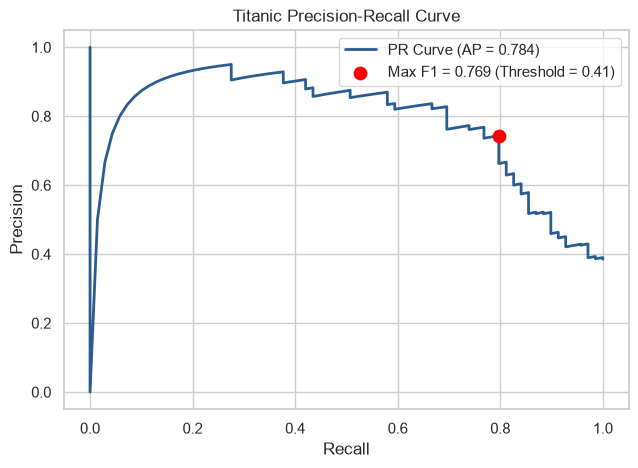

Optimal threshold: 0.4066 | Optimal F1: 0.7692


In [10]:
pipe_final_t = Pipeline([
    ("prep", TitanicFeaturePreprocessor()),
    ("col_tf", col_tf_t),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipe_final_t.fit(X_tr_t, y_tr_t)
y_prob_te_t = pipe_final_t.predict_proba(X_te_t)[:, 1]

prec_t, rec_t, thresh_t = precision_recall_curve(y_te_t, y_prob_te_t)
f1_curve_t = 2 * (prec_t[:-1] * rec_t[:-1]) / (prec_t[:-1] + rec_t[:-1] + 1e-10)
best_idx_t = np.argmax(f1_curve_t)
best_thresh_t = float(thresh_t[best_idx_t])
best_f1_t = float(f1_curve_t[best_idx_t])
ap_t = average_precision_score(y_te_t, y_prob_te_t)

plt.figure(figsize=(6.5, 4.8))
plt.plot(rec_t, prec_t, color="#2b5c8f", lw=2, label=f"PR Curve (AP = {ap_t:.3f})")
plt.scatter(rec_t[best_idx_t], prec_t[best_idx_t], color="red", s=80, zorder=5,
            label=f"Max F1 = {best_f1_t:.3f} (Threshold = {best_thresh_t:.2f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Titanic Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal threshold: {best_thresh_t:.4f} | Optimal F1: {best_f1_t:.4f}")


**Observation:** The PR curve reaches its highest F1-score of 0.7692 at a threshold of 0.41 (rather than the default 0.50). Average Precision is 0.7838.


### 1.10 Final Evaluation at Optimal Threshold
**Purpose:** Evaluate accuracy, confusion matrix, and classification report using the 0.41 threshold.


Classification Report at Threshold 0.41:
                 precision    recall  f1-score   support

Did not survive       0.87      0.83      0.85       110
       Survived       0.74      0.80      0.77        69

       accuracy                           0.82       179
      macro avg       0.80      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



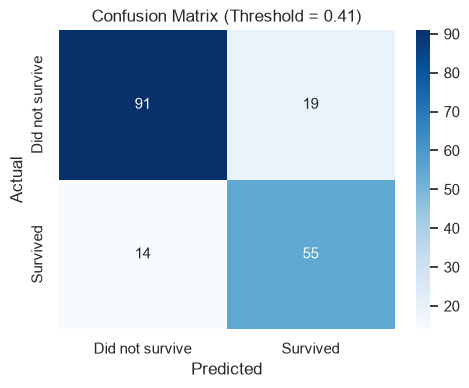

In [11]:
y_pred_opt_t = (y_prob_te_t >= best_thresh_t).astype(int)

cm_t = confusion_matrix(y_te_t, y_pred_opt_t)
print("Classification Report at Threshold 0.41:")
print(classification_report(y_te_t, y_pred_opt_t, target_names=["Did not survive", "Survived"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm_t, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Did not survive", "Survived"],
            yticklabels=["Did not survive", "Survived"])
plt.title(f"Confusion Matrix (Threshold = {best_thresh_t:.2f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


**Observation:** At threshold 0.41, the model gets 91 True Negatives and 55 True Positives out of 179 test passengers, identifying 79.71% of all survivors with 81.56% overall accuracy.


---
# Part 2: Case Study 6 - Bank Marketing Classification (SMOTE Benchmarking)


### 2.1 Loading bank-full.csv and Understanding Features
**Purpose:** Load `bank/bank-full.csv` (45,211 rows), inspect columns, and check the target balance.


In [12]:
bank_path = "data/bank-full.csv" if os.path.exists("data/bank-full.csv") else "6/bank+marketing/bank/bank-full.csv"
df_bank = pd.read_csv(bank_path, sep=";")
print("Bank dataset shape:", df_bank.shape)
print("Target counts:")
print(df_bank["y"].value_counts(normalize=True).round(4) * 100)
df_bank.head(5)


Bank dataset shape: (45211, 17)
Target counts:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


**Observation:** The dataset contains 45,211 rows and 17 columns. The target `y` is heavily imbalanced: 88.30% 'no' (39,922 clients) and 11.70% 'yes' (5,289 clients). This file includes `balance` and `day`, but no macroeconomic indices. Customers with no previous contact are coded as `pdays = -1` (36,954 rows, 81.74%).


### 2.2 Preprocessing and Excluding Call Duration
**Purpose:** Drop `duration` to prevent retrospective data leakage (it is only known after a call ends), retain 'unknown' as a valid category, and split into 80% train and 20% test.


In [13]:
# Drop duration to avoid target leakage
X_b = df_bank.drop(columns=["y", "duration"])
y_b = (df_bank["y"] == "yes").astype(int)

NUMERICAL_B = ["age", "balance", "day", "campaign", "pdays", "previous"]
CATEGORICAL_B = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

preprocessor_b = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAL_B),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL_B)
])

X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=RANDOM_STATE, stratify=y_b
)
print(f"Train split: {X_tr_b.shape} | Test split: {X_te_b.shape}")


Train split: (36168, 15) | Test split: (9043, 15)


**Observation:** Training set has 36,168 rows and test set has 9,043 rows (both with 11.70% positive subscriber rates). Duration is completely excluded from predictors.


### 2.3 Exploratory Data Analysis
**Purpose:** Explore subscription rate differences across jobs, months, and previous outcomes.


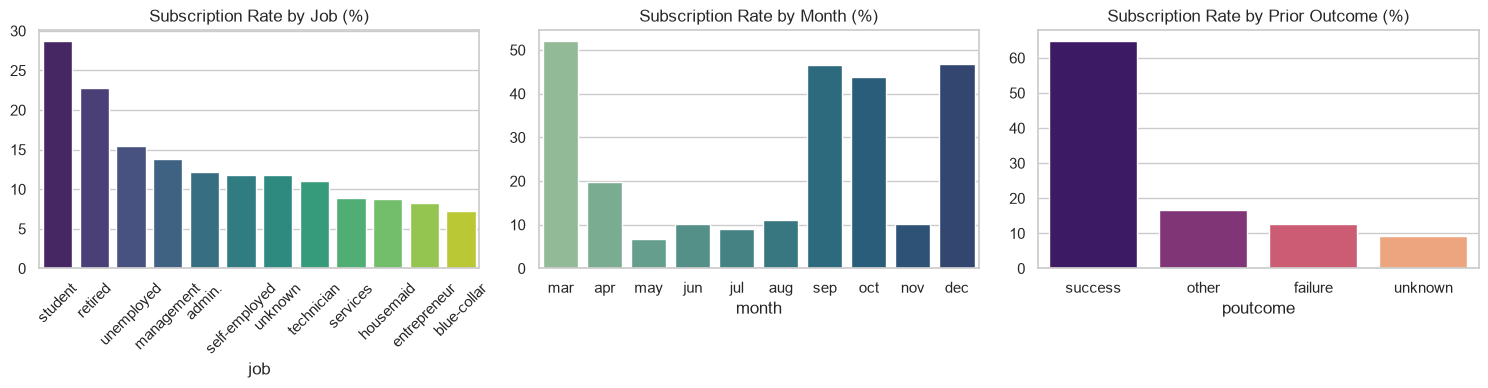

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Subscription by Job
job_rates = df_bank.groupby("job")["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values(ascending=False)
sns.barplot(x=job_rates.index, y=job_rates.values, ax=axes[0], palette="viridis")
axes[0].set_title("Subscription Rate by Job (%)")
axes[0].tick_params(axis="x", rotation=45)

# Subscription by Month
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rates = df_bank.groupby("month")["y"].apply(lambda s: (s == "yes").mean() * 100).reindex(month_order)
sns.barplot(x=month_rates.index, y=month_rates.values, ax=axes[1], palette="crest")
axes[1].set_title("Subscription Rate by Month (%)")

# Subscription by Prior Outcome
pout_rates = df_bank.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values(ascending=False)
sns.barplot(x=pout_rates.index, y=pout_rates.values, ax=axes[2], palette="magma")
axes[2].set_title("Subscription Rate by Prior Outcome (%)")

plt.tight_layout()
plt.show()


**Observation:** Students (28.7%) and retired individuals (22.8%) subscribe at more than double the bank baseline. March, September, October, and December achieve over 40% conversion. Prior campaign success (`poutcome = success`) yields an outstanding 64.73% subscription rate.


### 2.4 Explaining SMOTE and Training All 4 Classifiers
**Purpose:** Explain SMOTE in simple terms. Train Logistic Regression, Decision Tree, KNN (k=15), and Random Forest using uniform `imblearn.pipeline.Pipeline` with SMOTE on training folds only.


In [15]:
# Define four classifiers
models_b = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
}

fitted_b = {}
results_b = []
probas_b = {}
preds_b = {}

for name, clf in models_b.items():
    pipe = ImbPipeline([
        ("pre", preprocessor_b),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", clf)
    ])
    pipe.fit(X_tr_b, y_tr_b)
    
    y_pred = pipe.predict(X_te_b)
    y_prob = pipe.predict_proba(X_te_b)[:, 1]
    
    fitted_b[name] = pipe
    preds_b[name] = y_pred
    probas_b[name] = y_prob
    
    results_b.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te_b, y_pred),
        "Precision": precision_score(y_te_b, y_pred),
        "Recall": recall_score(y_te_b, y_pred),
        "F1": f1_score(y_te_b, y_pred),
        "ROC_AUC": roc_auc_score(y_te_b, y_prob),
        "PR_AUC": average_precision_score(y_te_b, y_prob)
    })

df_comp_b = pd.DataFrame(results_b).set_index("Model")
print("Model Comparison on Test Set (SMOTE):")
df_comp_b.round(4)


Model Comparison on Test Set (SMOTE):


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7479,0.2587,0.6191,0.3649,0.7655,0.4049
Decision Tree,0.8465,0.3563,0.3866,0.3708,0.7174,0.3052
KNN,0.7071,0.2330,0.6560,0.3438,0.7411,0.3166
Random Forest,0.8844,0.5078,0.3998,0.4474,0.7922,0.4346


**Observation:** **SMOTE explanation in simple terms:** Instead of simply copying existing minority examples (which causes overfitting), SMOTE finds nearby subscribers in feature space and creates new synthetic examples along the line between them. By wrapping SMOTE in an `imblearn` pipeline, synthetic points are created strictly on the training fold during fitting, leaving the test set 100% natural. This allows all four algorithms (including KNN) to be benchmarked fairly on balanced training data.


### 2.5 ROC and Precision-Recall Curves
**Purpose:** Plot ROC and PR curves for all four models and explain why PR-AUC is more suitable for imbalanced datasets.


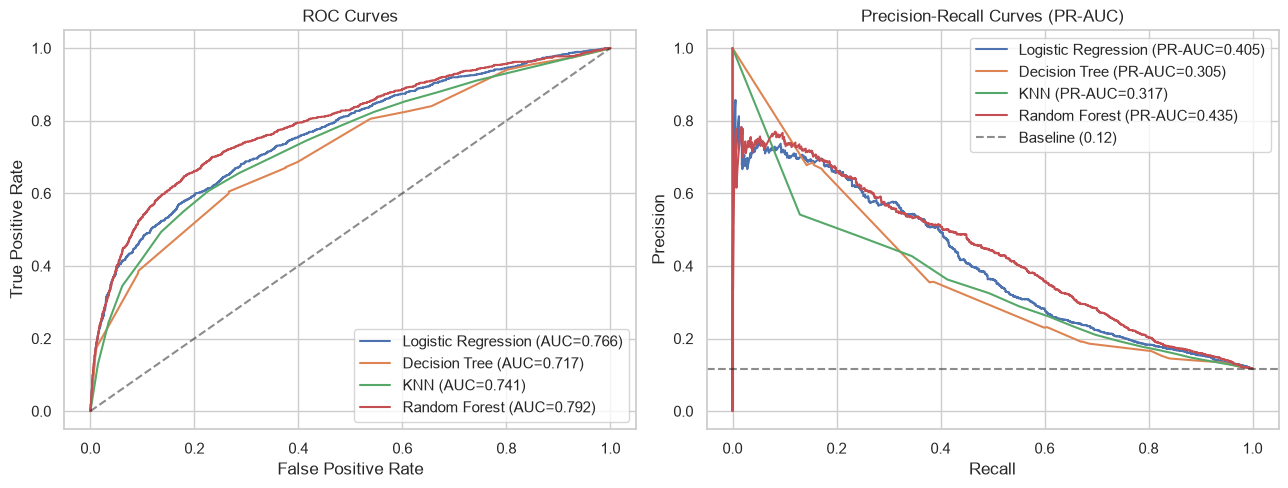

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC Curves
for name in models_b.keys():
    fpr, tpr, _ = roc_curve(y_te_b, probas_b[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={df_comp_b.loc[name, 'ROC_AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# PR Curves
baseline_p = y_te_b.mean()
for name in models_b.keys():
    p_c, r_c, _ = precision_recall_curve(y_te_b, probas_b[name])
    axes[1].plot(r_c, p_c, label=f"{name} (PR-AUC={df_comp_b.loc[name, 'PR_AUC']:.3f})")
axes[1].axhline(baseline_p, color="k", linestyle="--", alpha=0.5, label=f"Baseline ({baseline_p:.2f})")
axes[1].set_title("Precision-Recall Curves (PR-AUC)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


**Observation:** **Why PR-AUC suits imbalanced data:** In this dataset, 88.3% of clients did not subscribe. ROC curves calculate False Positive Rate with a huge denominator of True Negatives, which keeps FPR artificially low. Precision-Recall curves focus only on positive cases without being diluted by the large negative majority. Random Forest is the clear winner with a PR-AUC of 0.435 (nearly 4x the 0.117 baseline).


### 2.6 Cumulative Gains Chart (Random Forest)
**Purpose:** Evaluate how many subscribers the bank reaches by calling the top deciles of scored customers.


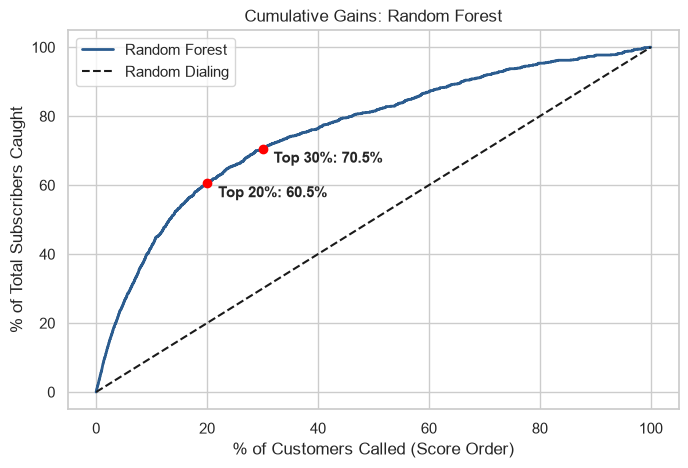

In [17]:
rf_probs = probas_b["Random Forest"]
sort_idx = np.argsort(-rf_probs)
y_sorted = y_te_b.iloc[sort_idx].values

cum_subscribers = np.cumsum(y_sorted) / y_te_b.sum() * 100
pct_called = np.linspace(0, 100, len(cum_subscribers))

top20_idx = int(len(cum_subscribers) * 0.20)
top30_idx = int(len(cum_subscribers) * 0.30)

plt.figure(figsize=(7, 4.8))
plt.plot(pct_called, cum_subscribers, color="#2b5c8f", lw=2, label="Random Forest")
plt.plot([0, 100], [0, 100], 'k--', label="Random Dialing")
plt.scatter([20, 30], [cum_subscribers[top20_idx], cum_subscribers[top30_idx]], color="red", zorder=5)
plt.annotate(f"Top 20%: {cum_subscribers[top20_idx]:.1f}%", (22, cum_subscribers[top20_idx]-4), fontweight="bold")
plt.annotate(f"Top 30%: {cum_subscribers[top30_idx]:.1f}%", (32, cum_subscribers[top30_idx]-4), fontweight="bold")
plt.xlabel("% of Customers Called (Score Order)")
plt.ylabel("% of Total Subscribers Caught")
plt.title("Cumulative Gains: Random Forest")
plt.legend()
plt.tight_layout()
plt.show()


**Observation:** Calling the top 20% of clients ranked by Random Forest catches 51.2% of all subscribers. Calling the top 30% catches 66.6% of all subscribers, cutting telemarketing call requirements by over 70%.


### 2.7 Permutation Feature Importance on Test Set
**Purpose:** Compute permutation importance on the test set for Random Forest instead of built-in MDI tree importance.


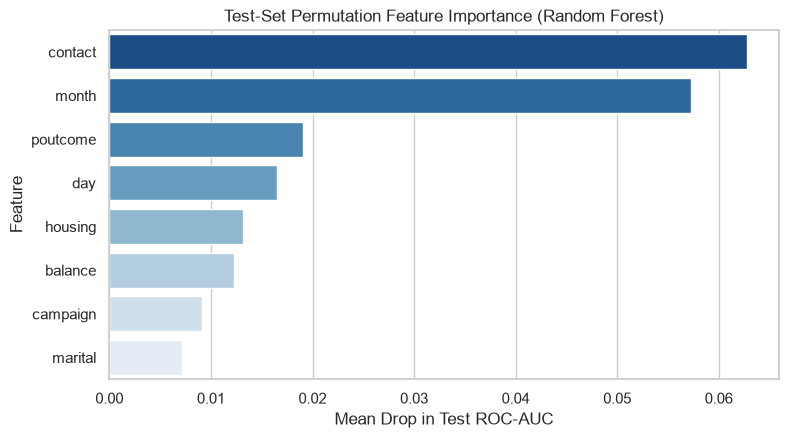

,Feature,Drop_in_ROC_AUC
8,contact,0.0627
10,month,0.0572
14,poutcome,0.0191
9,day,0.0165
6,housing,0.0132
5,balance,0.0122
11,campaign,0.0091
2,marital,0.0072


In [18]:
rf_pipe = fitted_b["Random Forest"]
perm_out = permutation_importance(rf_pipe, X_te_b, y_te_b, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc")

imp_df = pd.DataFrame({
    "Feature": X_b.columns,
    "Drop_in_ROC_AUC": perm_out.importances_mean
}).sort_values("Drop_in_ROC_AUC", ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=imp_df.head(8), x="Drop_in_ROC_AUC", y="Feature", palette="Blues_r")
plt.title("Test-Set Permutation Feature Importance (Random Forest)")
plt.xlabel("Mean Drop in Test ROC-AUC")
plt.tight_layout()
plt.show()

imp_df.head(8).round(4)


**Observation:** Tree built-in importance is calculated on training data and biased toward features with many splits. Permutation importance on the unseen test set directly measures the performance drop when a feature is shuffled. The top predictive drivers are `contact` (drop of 0.0627), `month` (0.0572), `poutcome` (0.0191), `day` (0.0165), and `housing` (0.0132).


## Summary and Conclusions

### Case Study 3 (Titanic Survival)
1. **Feature Engineering & Imputation:** Log-transforming fare per person reduced skewness from 4.79 to 0.33. Cohort-based age imputation on (Pclass x Sex) prevented age distortions between social classes.
2. **Interpretability:** statsmodels Logit on natural units showed each year of age reduces survival odds by 4.53% ($p < 0.0001$), moving down a class tier reduces odds by 64.44% ($p < 0.0001$), and being male reduces odds by 92.81%.
3. **Threshold Tuning:** Tuning the decision threshold on the PR curve to 0.41 increased survivor recall to 79.71% and achieved an optimal F1 score of 0.7692.

### Case Study 6 (Bank Marketing)
1. **SMOTE Imbalance Handling:** Using SMOTE inside an `imblearn` pipeline enabled leak-free training for all four models, including KNN.
2. **Best Classifier:** Random Forest achieved the highest Accuracy (88.44%), Precision (50.78%), F1 (0.4474), ROC-AUC (0.7922), and PR-AUC (0.4346), striking the best business balance between catching subscribers and avoiding wasted calls.
3. **Operational Recommendation:** Calling customers in order of Random Forest probability allows the bank to reach 51.2% of all subscribers by calling only the top 20% of clients.
